# K-Means Clustering Using the Elbow Method

## Objective
Implement K-Means clustering on a dataset containing at least 200 data points and two features: **Study Hours** and **IQ**. Use the Elbow Method to examine the optimal number of clusters and visualize the resulting clusters.

## Steps
1. Import the required libraries.
2. Generate a dataset with 200 data points.
3. Visualize the original dataset.
4. Select and standardize the features.
5. Calculate WCSS for different values of K.
6. Plot the Elbow Method graph.
7. Apply K-Means clustering and visualize the clusters.
8. Display the cluster centers.

## 1. Import Libraries
Import Pandas and NumPy for data handling, Matplotlib for visualization, and the required scikit-learn classes for scaling and clustering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## 2. Create the Dataset
Generate 200 sample records with two features:
- **Study Hours:** Daily study hours, generated between 1 and 12.
- **IQ:** IQ scores, generated between 80 and 149.

A fixed random seed makes the generated dataset reproducible.

In [2]:
# Create Dataset
np.random.seed(42)

df = pd.DataFrame({
    'Study Hours': np.random.uniform(1, 12, 200),
    'IQ': np.random.randint(80, 150, 200)
})

print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset:
   Study Hours   IQ
0     5.119941  103
1    11.457857  115
2     9.051933  117
3     7.585243  104
4     2.716205   97

Dataset Shape: (200, 2)


## 3. Visualize the Original Dataset
Create a scatter plot to observe the distribution of Study Hours and IQ before applying clustering.

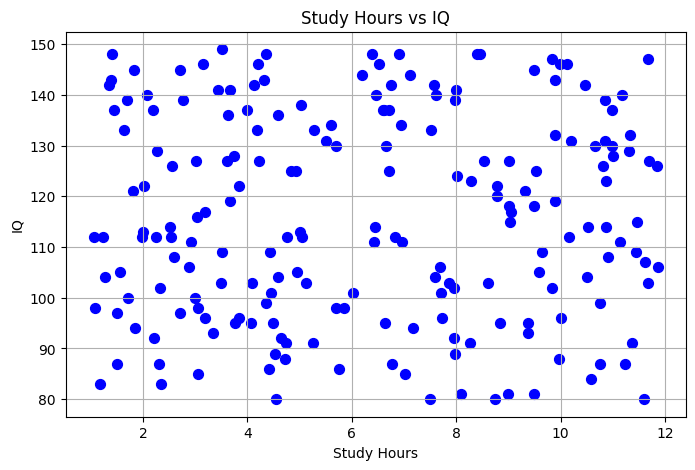

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Study Hours'],
    df['IQ'],
    color='blue',
    s=50
)

plt.title("Study Hours vs IQ")
plt.xlabel("Study Hours")
plt.ylabel("IQ")
plt.grid()
plt.show()

## 4. Select Features
Use the two required columns as input features for K-Means.

In [4]:
X = df[['Study Hours', 'IQ']]

## 5. Standardize the Data
Standardize both features so that differences in their numerical scales do not cause one feature to dominate the distance calculations used by K-Means.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 6. Calculate WCSS Using the Elbow Method
Fit K-Means models for values of K from 1 to 10. Store each model's **WCSS (Within-Cluster Sum of Squares)**, represented by `inertia_`. WCSS measures the sum of squared distances between each data point and its assigned cluster center.

In [6]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print("WCSS Values:")
for i, value in enumerate(wcss, start=1):
    print(f"Clusters: {i}, WCSS: {value:.2f}")

WCSS Values:
Clusters: 1, WCSS: 400.00
Clusters: 2, WCSS: 244.34
Clusters: 3, WCSS: 144.25
Clusters: 4, WCSS: 91.43
Clusters: 5, WCSS: 74.64
Clusters: 6, WCSS: 63.80
Clusters: 7, WCSS: 52.52
Clusters: 8, WCSS: 44.86
Clusters: 9, WCSS: 40.17
Clusters: 10, WCSS: 35.19


## 7. Plot the Elbow Method Graph
Plot the WCSS values against the number of clusters (K). Look for the point where the decrease in WCSS begins to slow down. This bend is called the **elbow** and can help identify a suitable K.

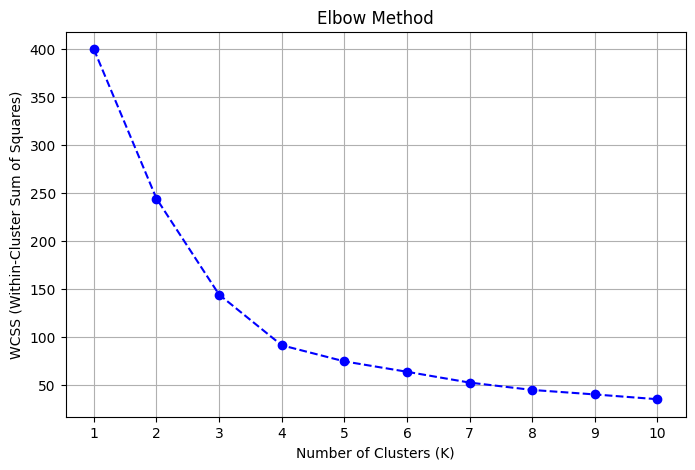

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    linestyle='--',
    color='blue'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

## 8. Apply K-Means Clustering
For the final visualization, use **K = 5** as a demonstration choice. In an analysis, choose K by examining the elbow graph rather than assuming that five clusters is always optimal.

In [8]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

## 9. Display the Clustered Dataset
Display the first ten rows with their assigned cluster labels and count the number of data points assigned to each cluster.

In [9]:
print("Clustered Dataset:")
print(df.head(10))

print("\nNumber of Data Points in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

Clustered Dataset:
   Study Hours   IQ  Cluster
0     5.119941  103        0
1    11.457857  115        2
2     9.051933  117        2
3     7.585243  104        3
4     2.716205   97        0
5     2.715940  145        4
6     1.638920  133        4
7    10.527938  114        2
8     7.612265  140        1
9     8.788798  120        2

Number of Data Points in Each Cluster:
Cluster
0    57
1    30
2    40
3    33
4    40
Name: count, dtype: int64


## 10. Visualize the Clusters and Centroids
Use different colors to show the five clusters. The red X markers represent the cluster centroids. Convert the centroids back to the original feature scale so they can be plotted alongside the unscaled data.

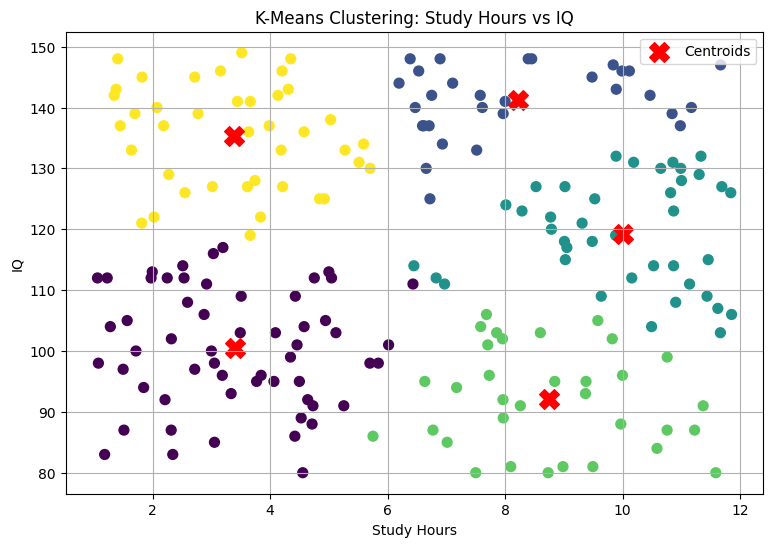

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df['Study Hours'],
    df['IQ'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("K-Means Clustering: Study Hours vs IQ")
plt.xlabel("Study Hours")
plt.ylabel("IQ")
plt.legend()
plt.grid()
plt.show()

## 11. Display Cluster Centers
Print the coordinates of each centroid in the original units of Study Hours and IQ.

In [11]:
print("Cluster Centers:")

print(pd.DataFrame(
    centers,
    columns=['Study Hours', 'IQ']
))

Cluster Centers:
   Study Hours          IQ
0     3.405998  100.438596
1     8.217732  141.166667
2    10.003738  119.250000
3     8.748952   92.090909
4     3.381872  135.250000


## Conclusion
K-Means clustering was applied to 200 data points using Study Hours and IQ as the two input features. The Elbow Method was used to calculate and visualize WCSS for K values from 1 to 10. The final scatter plot displays the assigned clusters and their centroids.

**Note:** The data is randomly generated and does not contain predefined groups. Therefore, the elbow may not be sharply defined. The choice of K = 5 in this notebook is for demonstration; it should be checked against the elbow plot.